# Week 1 — Run it, then discover a real truth yourself

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harjotsingh0311/flyrank-ml-internship/blob/main/notebooks/01_first_look_and_discovery.ipynb?flush_cache=true)

By the end of this notebook you will have:
1. **Run a real ML pipeline** on real (anonymized) search data and watched a learned model beat a hand-written rule.
2. **Rediscovered a real finding yourself** in ~10 lines of pandas.

No prior ML needed. Everything runs on the small anonymized dataset that ships with this repo — no credentials, no private data.

## 0. Setup (Colab or local)
On Colab this clones the repo and installs requirements. Locally, select **Python 3.13 (FlyRank ML)** in VS Code. The setup locates the repository safely on Windows and checks that the active kernel and required packages are correct before running any pipeline stage.


In [1]:
import os
import sys
import subprocess
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"
DATA_FILE = Path("data/raw/content_refresh_anonymized.csv")

if IN_COLAB:
    if not Path(REPO_DIR).is_dir() and not DATA_FILE.is_file():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    if not DATA_FILE.is_file():
        os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    start = Path.cwd().resolve()
    root = next((p for p in (start, *start.parents)
                 if (p / DATA_FILE).is_file() and (p / "scripts/run_all.py").is_file()), None)
    if root is None:
        raise FileNotFoundError("Open the cloned FlyRank project folder in VS Code and restart the kernel.")
    os.chdir(root)

    if os.name == "nt":
        expected_python = root / ".venv" / "Scripts" / "python.exe"
    else:
        expected_python = root / ".venv" / "bin" / "python"

    if expected_python.is_file():
        # Check the environment prefix (not resolved interpreter symlinks).
        if Path(sys.prefix).resolve() != (root / ".venv").resolve():
            raise RuntimeError(
                f"Wrong notebook kernel: {sys.executable}\n"
                f"Select Python 3.13 (FlyRank ML) or {expected_python} "
                "in VS Code, restart the kernel, and run this cell again."
            )

    required = ("pandas", "numpy", "sklearn", "matplotlib", "reportlab", "duckdb", "huggingface_hub")
    missing = [name for name in required if importlib.util.find_spec(name) is None]
    if missing:
        raise ModuleNotFoundError(
            f"Missing packages in active kernel: {', '.join(missing)}\n"
            f'Run in the terminal: uv pip install --python "{sys.executable}" -r requirements.txt ipykernel\n'
            "Then restart the notebook kernel and run all cells."
        )

print("Python interpreter:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Working dir:", os.getcwd())
assert DATA_FILE.is_file(), "Starter CSV not found."
print("Starter data found. You're ready.")


Python interpreter: c:\workstation\3RD YEAR\flyrank-ml-internship-starter\.venv\Scripts\python.exe
Python version: 3.13.13
Working dir: C:\workstation\3RD YEAR\flyrank-ml-internship-starter
Starter data found. You're ready.


## 1. Run the whole pipeline

This runs `scripts/run_all.py`: prepare features → baseline rule → train 3 models → evaluate → PDF.
It takes ~1 minute on the 30,000-row sample.

In [2]:
# Run all five stages using the verified notebook interpreter.
# An argument list handles Windows paths containing spaces safely.
subprocess.run(
    [sys.executable, str(Path("scripts/run_all.py").resolve())],
    cwd=Path.cwd(),
    check=True,
)
print("All five pipeline stages completed successfully.")


All five pipeline stages completed successfully.


### What just happened?
The pipeline ranked every page for "refresh review" two ways: a **hand-written rule baseline** and a **learned model**. Let's compare them on **Precision@50** — of the top 50 pages each says to fix first, how many are actually declining?

In [3]:
import json
res = json.load(open("outputs/model_results.json"))

base = res["baseline"]["baseline_precision_at_50"]
rf   = res["models"]["random_forest"]["precision_at_50"]

print(f"Hand-written rule  Precision@50: {base:.3f}   (~{round(base*50)} of the top 50 right)")
print(f"Random forest      Precision@50: {rf:.3f}   (~{round(rf*50)} of the top 50 right)")
print(f"\nThe learned model roughly {rf/base:.1f}x the rule on this metric.")
print("Validation split used:", res["split_strategy"], "(pages from a client are never in both train and test)")

Hand-written rule  Precision@50: 0.240   (~12 of the top 50 right)
Random forest      Precision@50: 0.680   (~34 of the top 50 right)

The learned model roughly 2.8x the rule on this metric.
Validation split used: client_holdout (pages from a client are never in both train and test)


You just ran a real ML system on real search data and saw a learned ranking beat a fixed rule. Now open `outputs/model_report.md` and skim it — that Markdown report is the *shape* of what your own capstone should produce.

## 2. Discover a real truth yourself

The safest, most satisfying early wins are **things you find in the data** — un-leakable, and they *are* the core lesson. Run the three cells below. Each is ~10 lines of pandas and each overturns a common SEO belief.

Every number is **computed live from the shipped CSV** — nothing is hardcoded.

In [4]:
import pandas as pd, numpy as np
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print(df.shape[0], "rows,", df.shape[1], "columns")
df.head(3)

30000 rows, 44 columns


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9


### Discovery A — "High search volume means more traffic." Does it?

In [5]:
corr = df["search_volume"].corr(df["impressions_90d"])
print(f"Correlation between search_volume and impressions_90d: {corr:.3f}")
print("Near zero -> keyword search volume barely predicts the traffic a page actually gets.")

Correlation between search_volume and impressions_90d: 0.001
Near zero -> keyword search volume barely predicts the traffic a page actually gets.


### Discovery B — the CTR cliff by position
Click-through rate is not flat: it collapses as you move down the results.

position_tier
page_1      0.3548
top_3       0.3341
striking    0.2558
page_3_5    0.1424
deep        0.0554


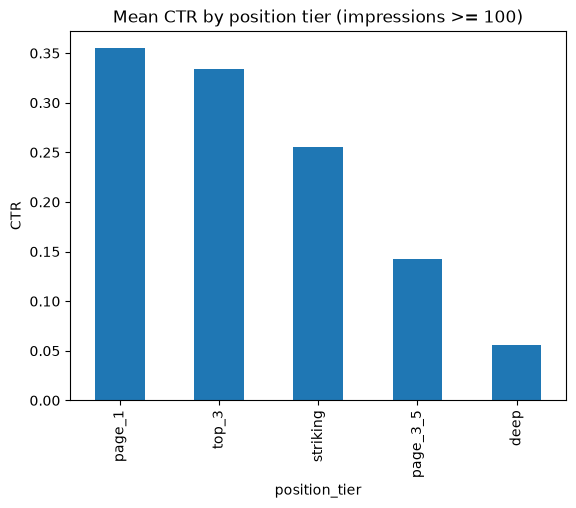

In [6]:
visible = df[df["impressions_90d"] >= 100]
ctr_by_pos = visible.groupby("position_tier")["ctr"].mean().sort_values(ascending=False)
print(ctr_by_pos.round(4).to_string())
ctr_by_pos.plot(kind="bar", title="Mean CTR by position tier (impressions >= 100)", ylabel="CTR");

### Discovery C — is longer content the lever?
Compare word count for **declining** vs **growing** pages.

In [7]:
wc = df.groupby("trend_direction")["word_count"].median()
print(wc.round(0).to_string())
print("\n'down' vs 'up' pages have almost the same median word count -> length is not the lever.")

trend_direction
down      2909.0
flat      2698.0
new       2239.0
stable    2912.0
up        2848.0

'down' vs 'up' pages have almost the same median word count -> length is not the lever.


## 3. 🔧 Your turn

Pick **one** of these and write a few lines below. This is your Week-1 discovery — you'll reference it in your Week-1 research-question write-up (on the InternHQ board).

- Redo Discovery A but only for pages with `impressions_90d > 0` — does the correlation change?
- In Discovery B, which `content_type` has the worst CTR *at the same position tier*?
- Find another belief to test: does `content_age_days` relate to `trend_direction`? Does `avg_position` relate to `ctr`?

**Rules:** describe what you observe as *observed / directional* — never "I proved Google's algorithm." Keep client data out of anything you publish.

Lowest CTR content type at each position tier:
position_tier       content_type  mean_ctr  median_ctr  page_count
         deep    keyword article    0.0555        0.00         869
       page_1 comparison article    0.1412        0.00         226
     page_3_5 comparison article    0.0940        0.00          63
     striking comparison article    0.1474        0.00          76
        top_3    keyword article    0.3104        0.19         527


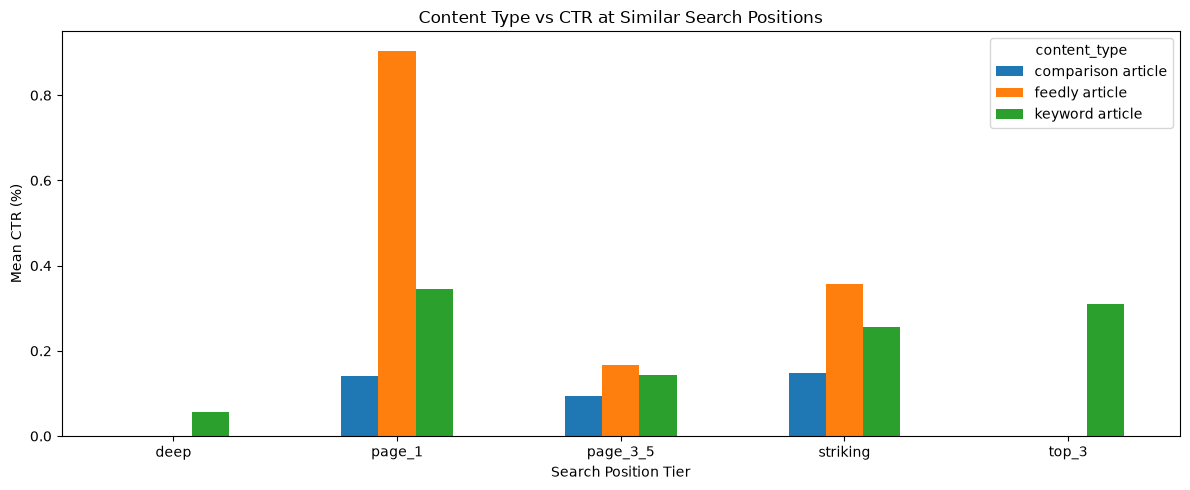

Interpretation: observed CTR differences within position tiers are directional, not evidence of a causal effect of content type.


In [8]:
# Your discovery here
# Discovery D: Does content type matter at the same search position?

# Load the bundled data independently so this cell also works after a kernel restart.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

start = Path.cwd().resolve()
relative_data = Path("data/raw/content_refresh_anonymized.csv")
data_path = next(
    (folder / relative_data for folder in (start, *start.parents)
     if (folder / relative_data).is_file()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        "Open the FlyRank repository folder in VS Code and rerun this cell."
    )

df = pd.read_csv(data_path)

sample = df[df["impressions_90d"] >= 100]

results = sample.groupby(["position_tier", "content_type"], observed=True).agg(
    mean_ctr=("ctr", "mean"),
    median_ctr=("ctr", "median"),
    page_count=("ctr", "count"),
).reset_index()

# Avoid drawing conclusions from very small groups.
results = results[results["page_count"] >= 30].copy()

if results.empty:
    print("No groups meet the minimum sample size of 30 pages.")
else:
    # Find the lowest mean CTR content type in each position tier.
    worst = results.loc[
        results.groupby("position_tier", observed=True)["mean_ctr"].idxmin()
    ]

    print("Lowest CTR content type at each position tier:")
    print(worst.round(4).to_string(index=False))

    results.pivot(
        index="position_tier",
        columns="content_type",
        values="mean_ctr",
    ).plot(
        kind="bar",
        figsize=(12, 5),
        title="Content Type vs CTR at Similar Search Positions",
        ylabel="Mean CTR (%)",
        xlabel="Search Position Tier",
        rot=0,
    )

    plt.tight_layout()
    plt.show()

    print(
        "Interpretation: observed CTR differences within position tiers "
        "are directional, not evidence of a causal effect of content type."
    )


### Save your work
**VS Code:** Run all cells using the FlyRank kernel, attempt the Your Turn exercise, and save with Ctrl+S. From the repo root, stage only `notebooks/01_first_look_and_discovery.ipynb` and commit/push it to your own GitHub repository. Do not commit additional data or generated pipeline artifacts.

**Colab:** *File → Save a copy in GitHub* (writes to your own repo — that's your submission) and *File → Save a copy in Drive* (so the session doesn't evaporate).

Next: `02_your_first_readable_model.ipynb` — where the model becomes a rule you can read.
